# Equilibrium Properties and Partial Ordering (Al-Fe and Al-Ni)

In [1]:
from pycalphad import Database, Model, Workspace, as_property, variables as v
import matplotlib.pyplot as plt

## Al-Fe (Heat Capacity and Degree of Ordering)
Here we compute equilibrium thermodynamic properties in the Al-Fe system. We know that only B2 and liquid are stable in the temperature range of interest, but we just as easily could have included all the phases in the calculation using `my_phases = list(db.phases.keys())`. Notice that the syntax for specifying a range is `(min, max, step)`. We can also directly specify a list of temperatures using the list syntax, e.g., `[300, 400, 500, 1400]`.

In [2]:
dbf = Database('alfe_sei.TDB')
components = ['AL', 'FE', 'VA']
my_phases = ['LIQUID', 'B2_BCC']
conditions = {v.X('AL'): 0.25, v.T: (300, 2000, 10), v.P: 101325, v.N: 1}
wks1 = Workspace(dbf, components , my_phases, conditions, calc_opts=dict(pdens=500))  # use higher point density for convergence near the ordering temperature


We also compute degree of ordering at fixed temperature as a function of composition.

In [3]:
conditions2 = {v.X('AL'): (0,1,0.01), v.T: 700, v.P: 101325, v.N: 1}
wks2 = Workspace(dbf, components, my_phases, conditions2)

### Plots
Next we plot the degree of ordering versus temperature. We can see that the decrease in the degree of ordering is relatively steady and continuous. This is indicative of a second-order transition from partially ordered B2 to disordered bcc (A2).

Text(0, 0.5, 'Degree of ordering')

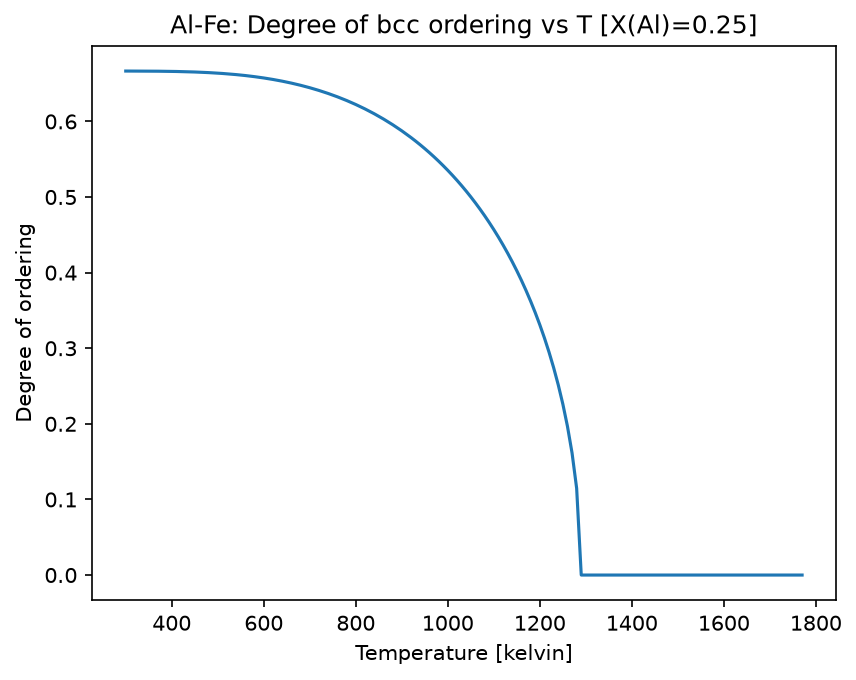

In [4]:
degree_of_ordering = as_property('degree_of_ordering(B2_BCC)')
degree_of_ordering.display_name = 'Degree of ordering'
fig, ax = plt.subplots(dpi=150)
ax.plot(wks1.get(v.T), wks1.get(degree_of_ordering))
ax.set_title('Al-Fe: Degree of bcc ordering vs T [X(Al)=0.25]')
ax.set_xlabel(f'{v.T.display_name} [{v.T.display_units}]')
ax.set_ylabel(f'{degree_of_ordering.display_name}')

For the heat capacity curve shown below we notice a sharp increase in the heat capacity around 730 K. This is indicative of a magnetic phase transition and, indeed, the temperature at the peak of the curve coincides with 75% of 1043 K, the Curie temperature of pure Fe. (Pure bcc Al is paramagnetic so it has an effective Curie temperature of 0 K.)

The decrease in heat capacity near 1280 K corresponds to the order-disorder transition observed in the above figure. We also observe a sharp jump in the heat capacity near 1800 K, corresponding to the melting of the bcc phase.

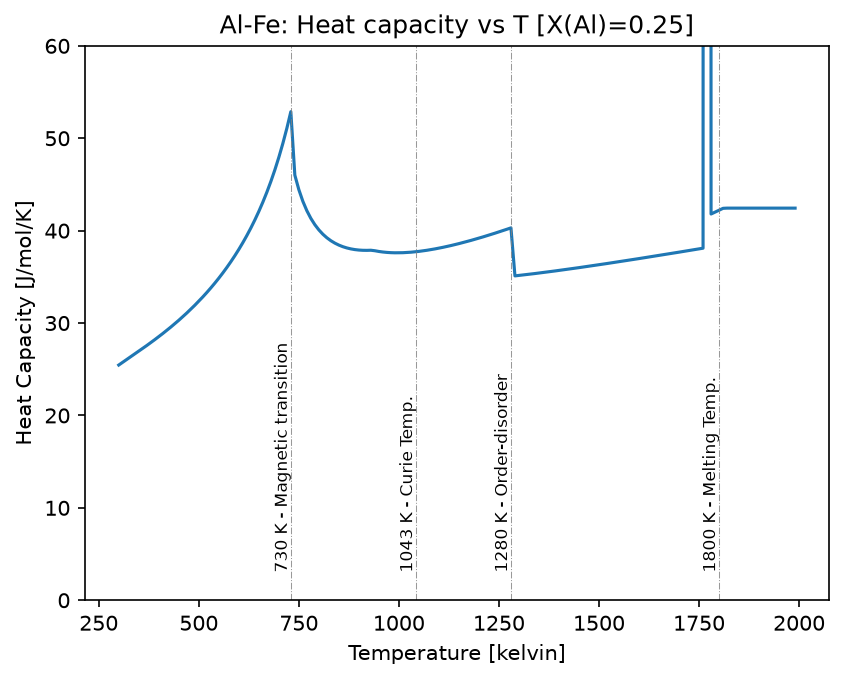

In [5]:
heat_capacity = as_property('HM.T')
heat_capacity.display_name = 'Heat Capacity'
heat_capacity.display_units = 'J/mol/K'
fig, ax = plt.subplots(dpi=150)
ax.plot(wks1.get(v.T), wks1.get(heat_capacity))
ax.set_title('Al-Fe: Heat capacity vs T [X(Al)=0.25]')
ax.set_xlabel(f'{v.T.display_name} [{v.T.display_units}]')
ax.set_ylabel(f'{heat_capacity.display_name} [{heat_capacity.display_units}]')
ax.set_ylim(0, 60)

critical_temperatures = [730, 1043, 1280, 1800]
special_labels = ['Magnetic transition', 'Curie Temp.', 'Order-disorder', 'Melting Temp.']
for idx, t in enumerate(critical_temperatures):
    ax.axvline(t, color='gray', linestyle='-.', linewidth=0.5, alpha=0.8)
    ax.text(t, 0.05, f"{t} K - {special_labels[idx]}", transform=ax.get_xaxis_transform(),
            rotation=90, va='bottom', ha='right', fontsize=8)

To understand more about what's happening around 700 K, we plot the degree of ordering versus composition. Note that this plot excludes all other phases except `B2_BCC`. We observe the presence of disordered bcc (A2) until around 13% Al or Fe, when the phase begins to order.

Text(0, 0.5, 'Degree of ordering')

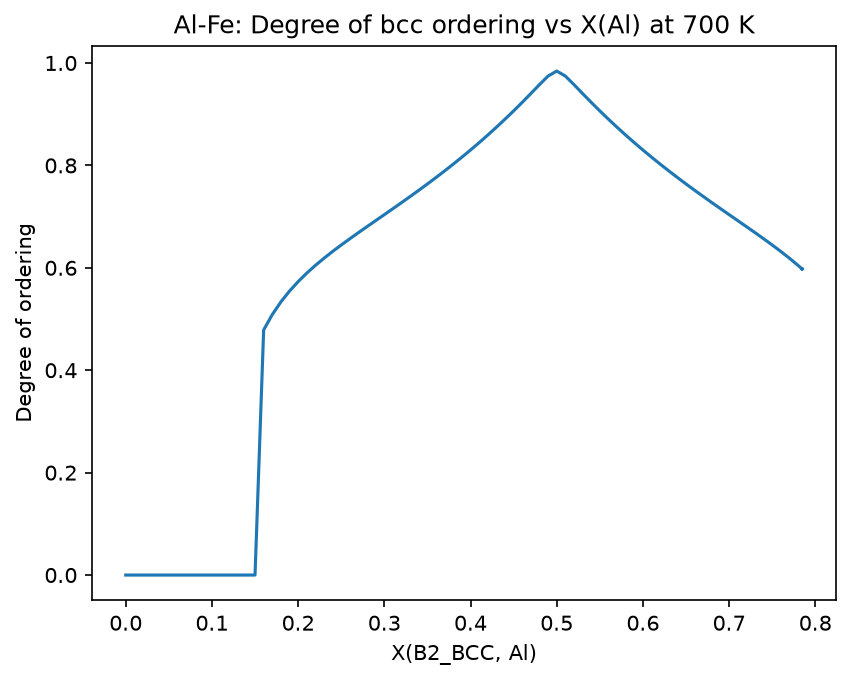

In [6]:
fig, ax = plt.subplots(dpi=150)
desired_phase = 'B2_BCC'
ax.plot(wks2.get(v.X(desired_phase, 'AL')), wks2.get(degree_of_ordering))
ax.set_title('Al-Fe: Degree of bcc ordering vs X(Al) at 700 K')
ax.set_xlabel(f"X(B2_BCC, Al)")
ax.set_ylabel(f'{degree_of_ordering.display_name}')

Notice that the plot abruptly ends around 0.8 fraction of Al, corresponding to the (metastable, because only liquid is entered) limit of stability of B2 on the phase diagram at this temperature. Because we want to plot in the metastable region, we will now tell `pycalphad` that we want to remove liquid from the calculation and then repeat it.

Text(0, 0.5, 'Degree of ordering')

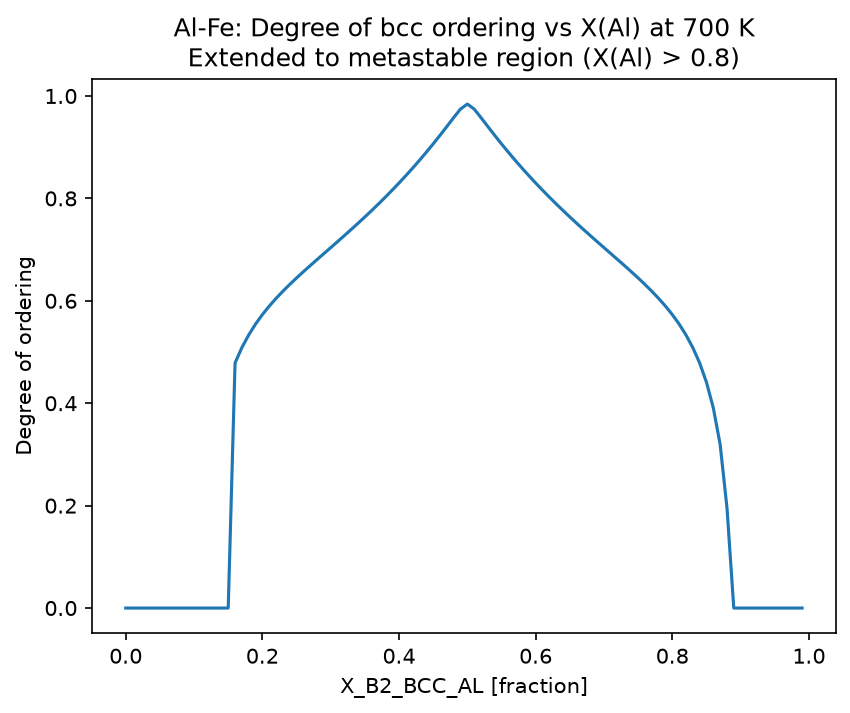

In [7]:
wks2.phases = [desired_phase]

fig, ax = plt.subplots(dpi=150)
ax.plot(wks2.get(v.X(desired_phase, 'AL')), wks2.get(degree_of_ordering))
ax.set_title('Al-Fe: Degree of bcc ordering vs X(Al) at 700 K\nExtended to metastable region (X(Al) > 0.8)')
ax.set_xlabel(f"{v.X(desired_phase, 'AL').display_name} [{v.X(desired_phase, 'AL').display_units}]")
ax.set_ylabel(f'{degree_of_ordering.display_name}')

### Site fractions across the ordering transition

A complementary view of the order/disorder transition is to look directly at the site fractions of each species on each sublattice. In the `B2_BCC` sublattice model (`(AL,FE)(AL,FE)(VA)`), the ordered state has Al preferentially occupying one substitutional sublattice and Fe the other; at the transition temperature, the site fractions on the two sublattices converge to the same overall value.

We restrict the calculation to `B2_BCC` only so the site fractions can be tracked into the metastable region without `LIQUID` interfering, and use a `Model` to enumerate the site-fraction symbols.

/tmp/ipykernel_2850815/2723021476.py:11: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(wks_sf.get(v.T), wks_sf.get(sf_sym), s=4, label=f'${sf_sym._latex()}$', c=colors[sf_sym.species])


Text(0, 0.5, 'Site fraction')

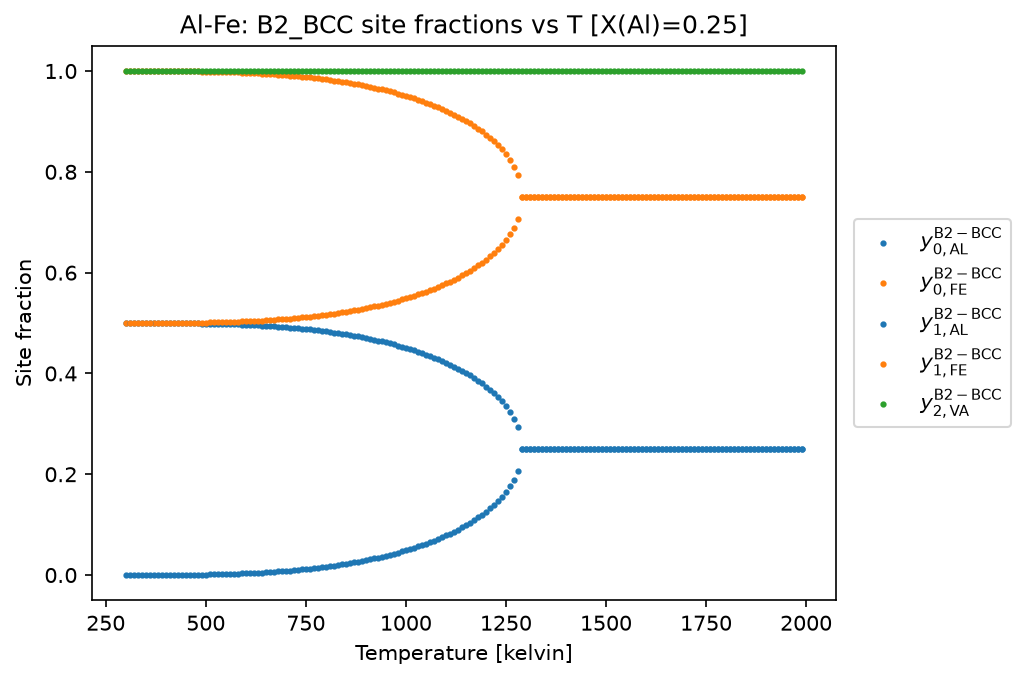

In [8]:
wks_sf = wks1.copy()
wks_sf.phases = ['B2_BCC']

mod = Model(dbf, components, 'B2_BCC')

fig, ax = plt.subplots(dpi=150)
# the sublattices for the B2 phase are equivalent by symmetry
# set up a color lookup dict to color lines by species
colors = dict(zip(sorted(set([sf.species for sf in mod.site_fractions])), plt.rcParams['axes.prop_cycle'].by_key()['color']))
for sf_sym in mod.site_fractions:
    ax.scatter(wks_sf.get(v.T), wks_sf.get(sf_sym), s=4, label=f'${sf_sym._latex()}$', c=colors[sf_sym.species])
ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5))
ax.set_title('Al-Fe: B2_BCC site fractions vs T [X(Al)=0.25]')
ax.set_xlabel(f'{v.T.display_name} [{v.T.display_units}]')
ax.set_ylabel('Site fraction')

## Al-Ni (Degree of Ordering)

In [9]:
db_alni = Database('NI_AL_DUPIN_2001.TDB')
components = ['AL', 'NI', 'VA']
phases = ['LIQUID', 'FCC_L12']
conditions = {v.X('AL'): 0.10, v.T: (300, 2500, 10), v.P: 101325}
wks3 = Workspace(db_alni, components, phases, conditions, calc_opts=dict(pdens=500))

### Plots
In the plot below we observe two phases designated `FCC_L12`. This is indicative of a miscibility gap. The ordered gamma-prime phase (`FCC#2`) steadily decreases in amount with increasing temperature until it completely disappears around `750 K`, leaving only the disordered gamma phase (`FCC#1`).

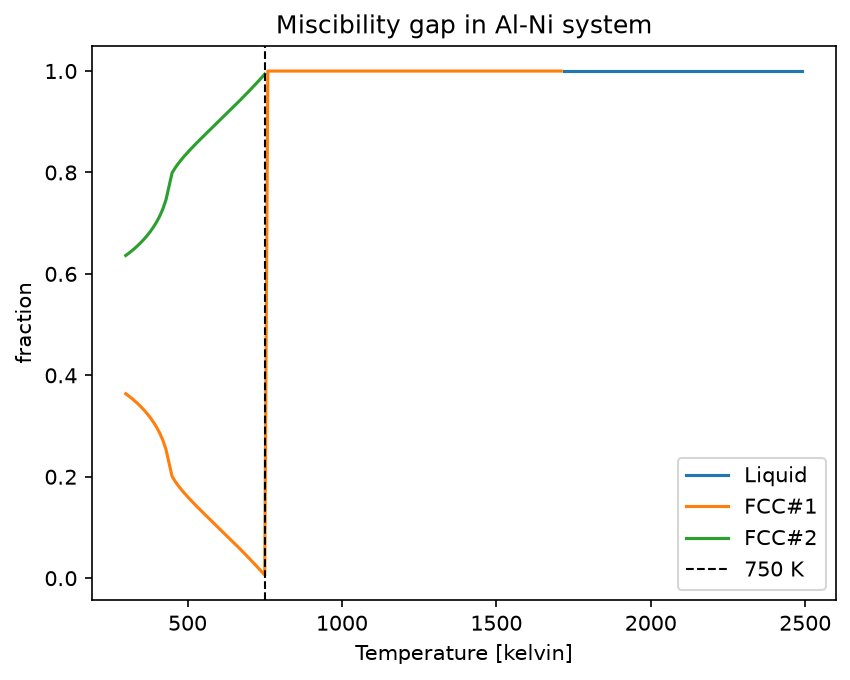

In [10]:
fig = plt.figure(dpi=150)
ax = fig.add_subplot()
ax.plot(wks3.get(v.T), wks3.get('NP(LIQUID)'), label='Liquid')
ax.plot(wks3.get(v.T), wks3.get('NP(FCC_L12#1)'), label='FCC#1')
ax.plot(wks3.get(v.T), wks3.get('NP(FCC_L12#2)'), label='FCC#2')
ax.axvline(750, color='k', linestyle='--', linewidth=1, label='750 K')
ax.set_title("Miscibility gap in Al-Ni system")
ax.set_xlabel(f'{v.T.display_name} [{v.T.display_units}]')
ax.set_ylabel('fraction')
ax.legend()

In the plot below we see that the degree of ordering does not change at all in each phase. There is a very abrupt disappearance of the completely ordered gamma-prime phase, leaving the completely disordered gamma phase. This is a first-order phase transition.

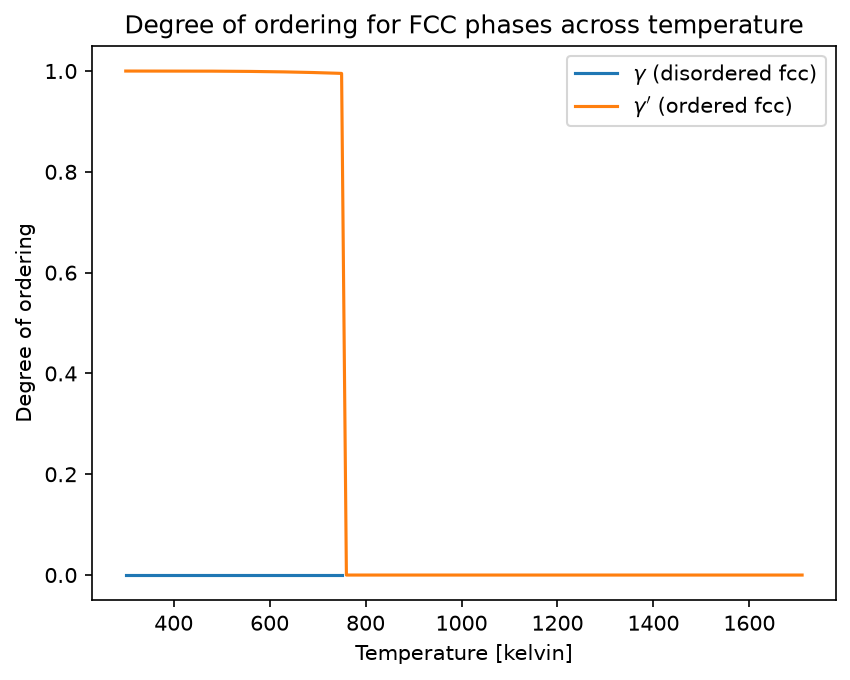

In [11]:
dis_degree_of_ordering = as_property('degree_of_ordering(FCC_L12#2)')
dis_degree_of_ordering.display_name = '$\\gamma$ (disordered fcc)'

L12_degree_of_ordering = as_property('degree_of_ordering(FCC_L12#1)')
L12_degree_of_ordering.display_name = '$\\gamma^\\prime$ (ordered fcc)'

fig = plt.figure(dpi=150)
ax = fig.add_subplot()
ax.plot(wks3.get(v.T), wks3.get(dis_degree_of_ordering),
        label=dis_degree_of_ordering.display_name)

ax.plot(wks3.get(v.T), wks3.get(L12_degree_of_ordering),
        label=L12_degree_of_ordering.display_name)

ax.set_title("Degree of ordering for FCC phases across temperature")
ax.set_ylabel("Degree of ordering")
ax.set_xlabel(f'{v.T.display_name} [{v.T.display_units}]')
ax.legend()